# Проверка предметов по фото — EDA и сравнение моделей

В игре ребёнок получает задание найти предмет и фотографирует его. Модель должна определить, есть ли этот предмет на снимке. В этом ноутбуке исследуем COCO val2017 и сравниваем три предобученные модели — MobileCLIP-S0, YOLOv8n и YOLO11n.

В исходном списке игры 58 заданий. Сначала проверим, для каких из них в COCO есть подходящая разметка и достаточно фотографий. Затем сравним модели на одном наборе классов и на всех 5 000 изображениях.

## 1. Подготовка окружения

Ноутбук рассчитан на Kaggle с включёнными Internet и GPU T4. Для воспроизводимости фиксируем версии библиотек, seed 2026 и порядок изображений по COCO ID. В конце сохраняем настройки эксперимента, версии пакетов и контрольные суммы весов.

In [1]:
import subprocess
import sys

PACKAGES = [
    "ultralytics==8.4.207",
    "scikit-learn==1.9.1",
    "open_clip_torch==4.2.1",
    "timm==1.0.31",
    "ftfy==6.3.1",
    "pycocotools==2.0.10",
]
MOBILECLIP_COMMIT = "48faa0fea4b08d74188b3841771aca6ff2c92852"
MOBILECLIP_SOURCE = "git+https://github.com/apple/ml-mobileclip.git@" + MOBILECLIP_COMMIT
_ = subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
_ = subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "--no-deps",
        MOBILECLIP_SOURCE,
    ]
)

In [2]:
import hashlib
import importlib.metadata
import io
import json
import math
import os
import platform
import random
import textwrap
import time
import urllib.request
import zipfile
from collections import Counter, defaultdict
from contextlib import redirect_stdout
from datetime import UTC, datetime
from pathlib import Path

# Set before the first CUDA operation for deterministic matrix multiplication.
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from PIL import Image, UnidentifiedImageError
from scipy.stats import binom
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
SEED = 2026
CV_SPLITS = 5
MIN_POSITIVE_IMAGES = 100
PROJECT_TASK_COUNT = 58
FAR_TARGET = 0.05
CONFIDENCE = 0.95
OUTPUT = Path(f"/kaggle/working/photoquest-coco-min{MIN_POSITIVE_IMAGES}")
OUTPUT.mkdir(parents=True, exist_ok=True)
STARTED_UTC = datetime.now(UTC).isoformat()
STARTED = time.perf_counter()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
torch.set_float32_matmul_precision("highest")
if not torch.cuda.is_available():
    raise RuntimeError("Kaggle Settings → Accelerator → GPU T4")
DEVICE = torch.device("cuda:0")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__, "Seed:", SEED)

GPU: Tesla T4
PyTorch: 2.11.0+cu130 Seed: 2026


## 2. Какие задания можно проверить на COCO

В COCO размечены предметы на фотографиях. Для каждого снимка известны классы объектов и их рамки. Одно фото может содержать несколько предметов, поэтому проверяем каждое задание отдельно. Например, снимок с кошкой и собакой подходит для обоих заданий. Для задания «найди банан» этот же снимок будет отрицательным примером, если банана в разметке нет.

Из 58 игровых заданий 38 совпадают с категориями COCO по смыслу. В остальных случаях разметки недостаточно. Например, метка `bottle` говорит, что на фото есть бутылка. Чтобы проверить задание «найди шампунь», нужно ещё определить её содержимое или назначение. Таких сведений в метке COCO нет, поэтому она подходит для задания «бутылка», а шампунь потребует отдельной разметки.

Ниже выведем классы, представленные в COCO. В следующем разделе оставим для сравнения те игровые классы, для которых набралось достаточно фотографий.

In [4]:
# Категории COCO, соответствующие заданиям игры.
COCO_TASK_CLASSES = [
    "bottle",
    "refrigerator",
    "microwave",
    "toaster",
    "bed",
    "tv",
    "clock",
    "potted plant",
    "teddy bear",
    "vase",
    "scissors",
    "laptop",
    "cell phone",
    "keyboard",
    "mouse",
    "sink",
    "toilet",
    "toothbrush",
    "umbrella",
    "backpack",
    "skateboard",
    "tie",
    "banana",
    "apple",
    "orange",
    "broccoli",
    "pizza",
    "sandwich",
    "cake",
    "bicycle",
    "car",
    "bus",
    "dog",
    "cat",
    "bird",
    "kite",
    "airplane",
    "train",
]
assert len(COCO_TASK_CLASSES) == len(set(COCO_TASK_CLASSES)) == 38

In [5]:
import kagglehub

# Attached Kaggle input is reused; otherwise download the named dataset.
DATA_ROOT = Path(kagglehub.dataset_download("nikitamanaenkov/microsoft-coco-2017"))
annotation_paths = sorted(DATA_ROOT.rglob("instances_val2017.json"))
if not annotation_paths:
    raise FileNotFoundError("Нужен instances_val2017.json, не keypoints JSON")
ANNOTATION_PATH = annotation_paths[0]
coco = json.loads(ANNOTATION_PATH.read_text(encoding="utf-8"))
coco_root = ANNOTATION_PATH.parent.parent
IMAGE_DIR = next(
    (p for p in (coco_root / "val2017", coco_root / "images" / "val2017") if p.is_dir()),
    None,
)
if IMAGE_DIR is None:
    raise FileNotFoundError("Не найдена папка val2017 с JPEG")
images = sorted(coco["images"], key=lambda row: row["id"])
annotations = coco["annotations"]
categories = {row["id"]: row["name"] for row in coco["categories"]}
image_by_id = {row["id"]: row for row in images}
assert len(images) == 5000
assert set(COCO_TASK_CLASSES).issubset(categories.values())
display(
    Markdown(
        f"В COCO val2017 **{len(images):,} фотографий**, "
        f"{len(annotations):,} размеченных объектов и "
        f"{len(categories)} классов.\n\n"
        + ", ".join(f"`{name}`" for name in sorted(categories.values()))
        + "."
    )
)

В COCO val2017 **5,000 фотографий**, 36,781 размеченных объектов и 80 классов.

`airplane`, `apple`, `backpack`, `banana`, `baseball bat`, `baseball glove`, `bear`, `bed`, `bench`, `bicycle`, `bird`, `boat`, `book`, `bottle`, `bowl`, `broccoli`, `bus`, `cake`, `car`, `carrot`, `cat`, `cell phone`, `chair`, `clock`, `couch`, `cow`, `cup`, `dining table`, `dog`, `donut`, `elephant`, `fire hydrant`, `fork`, `frisbee`, `giraffe`, `hair drier`, `handbag`, `horse`, `hot dog`, `keyboard`, `kite`, `knife`, `laptop`, `microwave`, `motorcycle`, `mouse`, `orange`, `oven`, `parking meter`, `person`, `pizza`, `potted plant`, `refrigerator`, `remote`, `sandwich`, `scissors`, `sheep`, `sink`, `skateboard`, `skis`, `snowboard`, `spoon`, `sports ball`, `stop sign`, `suitcase`, `surfboard`, `teddy bear`, `tennis racket`, `tie`, `toaster`, `toilet`, `toothbrush`, `traffic light`, `train`, `truck`, `tv`, `umbrella`, `vase`, `wine glass`, `zebra`.

In [6]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

In [7]:
# Fix the annotation snapshot, even when Kaggle dataset versions change.
EXPECTED_ANNOTATION_SHA256 = "e8c7f7908f1d7278341fae127d0da654f102f11bd7b21d8aeefa635b8c810b6f"
annotation_hash = sha256(ANNOTATION_PATH)
assert (
    annotation_hash == EXPECTED_ANNOTATION_SHA256
), "Снимок аннотаций изменился: проверь источник до сравнения"

## 3. Состав и качество данных

Сначала проверим, что все изображения читаются, их размеры совпадают с метаданными, а рамки и идентификаторы записаны корректно. Затем посмотрим, сколько фотографий приходится на каждый игровой класс, насколько крупно сняты предметы и какие из них встречаются вместе.

Число фотографий и число объектов считаем отдельно. Несколько бутылок на одном снимке дают один положительный пример для задания «бутылка». Групповая разметка `iscrowd` тоже подтверждает присутствие класса. При анализе размеров используем рамки отдельных объектов, поскольку общая рамка группы описывает сразу несколько предметов.

In [8]:
def audit_annotations():
    issues = Counter(
        {
            "unknown_reference": 0,
            "invalid_bbox": 0,
            "duplicate_bbox": 0,
            "duplicate_image_id": 0,
            "duplicate_annotation_id": 0,
        }
    )
    bbox_keys = Counter()
    for ann in annotations:
        image = image_by_id.get(ann["image_id"])
        if image is None or ann["category_id"] not in categories:
            issues["unknown_reference"] += 1
            continue
        x, y, width, height = ann["bbox"]
        if (
            width <= 0
            or height <= 0
            or x < 0
            or y < 0
            or x + width > image["width"] + 1
            or y + height > image["height"] + 1
        ):
            issues["invalid_bbox"] += 1
        key = (ann["image_id"], ann["category_id"], tuple(ann["bbox"]))
        bbox_keys[key] += 1
    issues["duplicate_bbox"] = sum(v - 1 for v in bbox_keys.values())
    for name, items in (("image", images), ("annotation", annotations)):
        ids = [item["id"] for item in items]
        issues[f"duplicate_{name}_id"] = len(ids) - len(set(ids))
    return dict(issues)


annotation_audit = audit_annotations()
display(pd.Series(annotation_audit, name="count").to_frame())
assert not any(annotation_audit.values()), annotation_audit

,count
unknown_reference,0
invalid_bbox,0
duplicate_bbox,0
duplicate_image_id,0
duplicate_annotation_id,0


In [9]:
def audit_images():
    records = []
    for item in tqdm(images, desc="Проверка всех JPEG"):
        path = IMAGE_DIR / item["file_name"]
        status = "ok"
        digest = None
        try:
            with Image.open(path) as image:
                image.verify()
            with Image.open(path) as image:
                if image.size != (item["width"], item["height"]):
                    status = "wrong_dimensions"
            digest = sha256(path)
        except FileNotFoundError:
            status = "missing"
        except (OSError, UnidentifiedImageError, ValueError):
            status = "corrupt"
        records.append(
            {
                "image_id": item["id"],
                "file_name": item["file_name"],
                "status": status,
                "sha256": digest,
            }
        )
    return pd.DataFrame(records)


image_audit = audit_images()
image_audit.to_csv(OUTPUT / "image_audit.csv", index=False)
assert image_audit["status"].eq("ok").all()
exact_duplicates = int(image_audit["sha256"].duplicated().sum())
display(
    Markdown(
        f"Все **{len(image_audit):,} JPEG** читаются, размеры совпадают "
        f"с метаданными. Точных дубликатов файлов — {exact_duplicates}."
    )
)

# Сохраняем сведения о лицензиях из метаданных датасета.
license_counts = Counter(item["license"] for item in images)
licenses = pd.DataFrame(
    [
        {
            "license_id": item["id"],
            "name": item["name"],
            "url": item["url"],
            "image_count": license_counts[item["id"]],
        }
        for item in coco["licenses"]
    ]
)
licenses.to_csv(OUTPUT / "licenses.csv", index=False)

Проверка всех JPEG:   0%|          | 0/5000 [00:00<?, ?it/s]

Все **5,000 JPEG** читаются, размеры совпадают с метаданными. Точных дубликатов файлов — 0.

In [10]:
class_instances = Counter()
small_instances = Counter()
label_sets = defaultdict(set)
for ann in annotations:
    name = categories[ann["category_id"]]
    if name not in COCO_TASK_CLASSES:
        continue
    label_sets[ann["image_id"]].add(name)
    if not ann.get("iscrowd", 0):
        class_instances[name] += 1
        image = image_by_id[ann["image_id"]]
        fraction = ann["bbox"][2] * ann["bbox"][3]
        fraction /= image["width"] * image["height"]
        small_instances[name] += fraction < 0.01

image_ids = np.array([item["id"] for item in images])
candidate_labels = np.array(
    [[name in label_sets[item["id"]] for name in COCO_TASK_CLASSES] for item in images],
    dtype=np.uint8,
)
class_stats = pd.DataFrame(
    {
        "target": COCO_TASK_CLASSES,
        "positive_images": candidate_labels.sum(axis=0),
        "individual_objects": [class_instances[t] for t in COCO_TASK_CLASSES],
        "small_object_share": [
            small_instances[t] / class_instances[t] if class_instances[t] else np.nan
            for t in COCO_TASK_CLASSES
        ],
    }
)
class_stats["included_in_benchmark"] = class_stats["positive_images"] >= MIN_POSITIVE_IMAGES
class_stats.to_csv(OUTPUT / "class_stats.csv", index=False)

# Фильтр применяем до запуска моделей и расчёта всех метрик.
included = class_stats["included_in_benchmark"].to_numpy()
selected_stats = class_stats.loc[included].copy()
excluded_stats = class_stats.loc[~included].copy()
TARGETS = selected_stats["target"].tolist()
assert TARGETS, "Для выбранного минимума в COCO нет подходящих классов"
labels = candidate_labels[:, included]
assert labels.shape == (len(images), len(TARGETS))
prompt_aliases = {"tv": "television", "mouse": "computer mouse"}
PROMPTS = {target: prompt_aliases.get(target, target) for target in TARGETS}

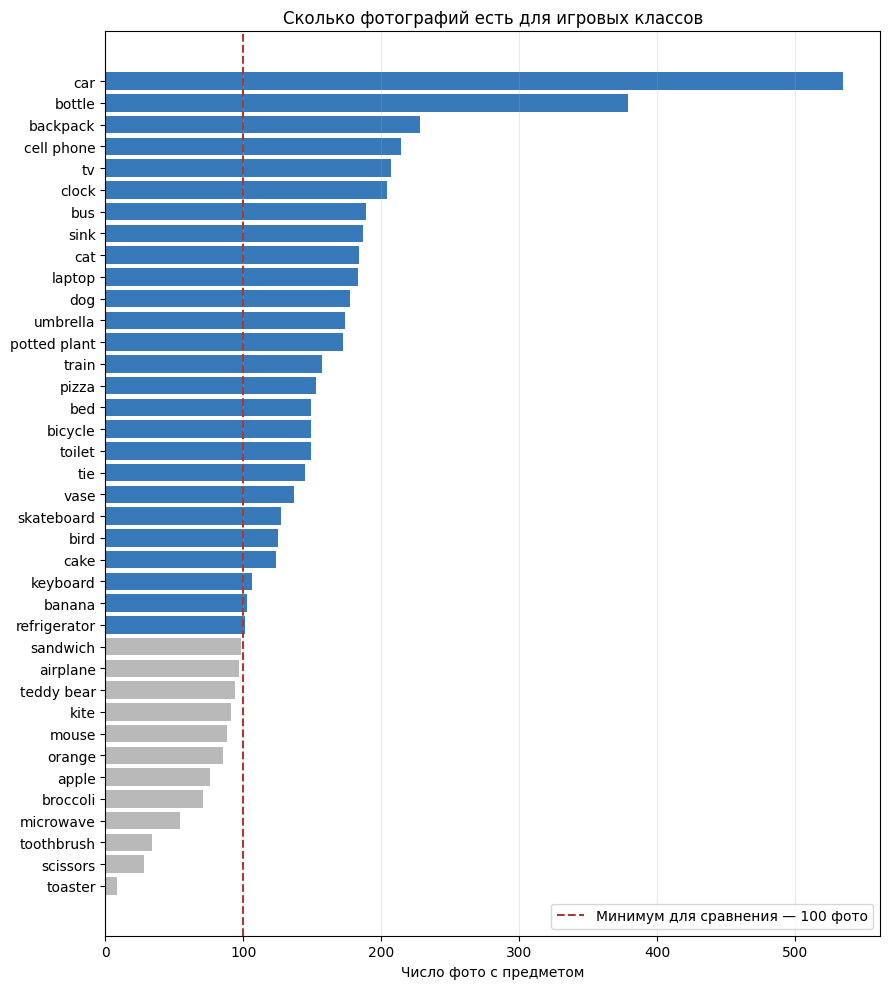

Для сравнения оставляем **26 классов** с минимум 100 положительными фотографиями. `bottle`, `refrigerator`, `bed`, `tv`, `clock`, `potted plant`, `vase`, `laptop`, `cell phone`, `keyboard`, `sink`, `toilet`, `umbrella`, `backpack`, `skateboard`, `tie`, `banana`, `pizza`, `cake`, `bicycle`, `car`, `bus`, `dog`, `cat`, `bird`, `train`.

Ещё 12 классов исключаем из расчёта метрик из-за нехватки примеров. `toaster` (8 фото), `scissors` (28 фото), `toothbrush` (34 фото), `microwave` (54 фото), `broccoli` (71 фото), `apple` (76 фото), `orange` (85 фото), `mouse` (88 фото), `kite` (91 фото), `teddy bear` (94 фото), `airplane` (97 фото), `sandwich` (98 фото).

Доля положительных фото для оставшихся классов составляет от **2.0% до 10.7%**. Для каждого задания отрицательных примеров значительно больше, поэтому доля правильных ответов сама по себе мало говорит о качестве.

In [11]:
ordered = class_stats.sort_values("positive_images")
colors = np.where(ordered["included_in_benchmark"], "#3879b9", "#b9b9b9")
fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(ordered["target"], ordered["positive_images"], color=colors)
ax.axvline(
    MIN_POSITIVE_IMAGES,
    color="#a33c32",
    linestyle="--",
    label=f"Минимум для сравнения — {MIN_POSITIVE_IMAGES} фото",
)
ax.set(title="Сколько фотографий есть для игровых классов", xlabel="Число фото с предметом")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT / "class_coverage.png", dpi=150)
plt.show()

selected_names = ", ".join(f"`{name}`" for name in TARGETS)
excluded_names = ", ".join(
    f"`{row.target}` ({row.positive_images} фото)"
    for row in excluded_stats.sort_values("positive_images").itertuples()
)
prevalence = selected_stats["positive_images"] / len(images)
display(
    Markdown(
        f"Для сравнения оставляем **{len(TARGETS)} классов** с минимум "
        f"{MIN_POSITIVE_IMAGES} положительными фотографиями. {selected_names}.\n\n"
        f"Ещё {len(excluded_stats)} классов исключаем из расчёта метрик из-за "
        f"нехватки примеров. {excluded_names}.\n\n"
        f"Доля положительных фото для оставшихся классов составляет "
        f"от **{prevalence.min():.1%} до {prevalence.max():.1%}**. "
        "Для каждого задания отрицательных примеров значительно больше, "
        "поэтому доля правильных ответов сама по себе мало говорит о качестве."
    )
)

Порог в 100 фотографий выбираем до сравнения моделей. При пяти фолдах это даёт хотя бы 20 положительных примеров в каждой оценочной части. В итоговом recall один ответ меняет результат максимум на один процентный пункт. У класса с восемью фотографиями шаг был бы 12,5 процентного пункта, что слишком грубо для сравнения.

Такой минимум уменьшает влияние единичных примеров. Для более точной оценки отдельных игровых заданий понадобится больше целевых фотографий.

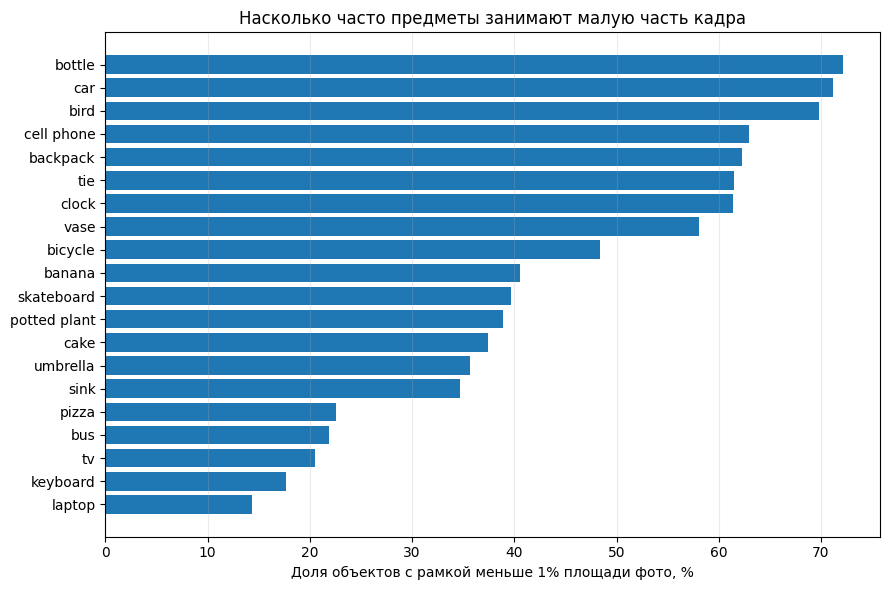

In [12]:
ordered_small = selected_stats.sort_values("small_object_share").tail(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ordered_small["target"], 100 * ordered_small["small_object_share"])
ax.set(
    title="Насколько часто предметы занимают малую часть кадра",
    xlabel="Доля объектов с рамкой меньше 1% площади фото, %",
)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT / "small_objects.png", dpi=150)
plt.show()

Бутылки и телефоны часто занимают меньше 1% площади кадра. Это важно для выбора подхода. MobileCLIP строит общее представление изображения после штатной предобработки 256×256, поэтому маленький предмет может потеряться среди деталей сцены. YOLO ищет отдельные объекты и возвращает их рамки. Дальше сравним, как это различие отражается на качестве по классам.

Границу в 1% используем для описания относительного размера предмета. В метрике рамок COCOeval применяются стандартные правила COCO, где размер определяется площадью в пикселях.

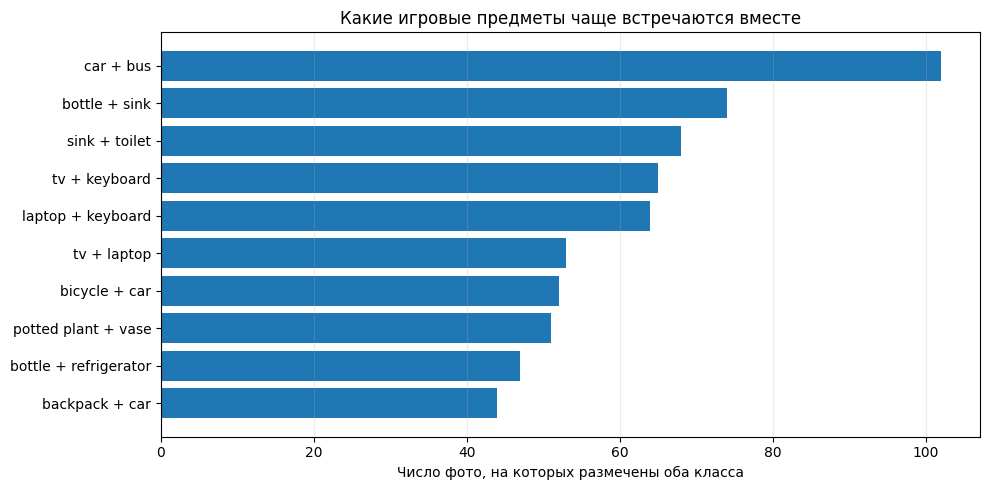

Хотя бы один выбранный класс размечен на **3,027 фото**. На **1,188 фото** таких классов несколько. Ещё **1,973 фото** имеют только другие метки COCO и служат отрицательными примерами для всех выбранных заданий. Для конкретного задания отрицательными также считаются все остальные снимки, на которых отсутствует его метка.

In [13]:
# int64 сохраняет корректные счётчики при числе фото больше 255.
cooccurrence = labels.astype(np.int64).T @ labels.astype(np.int64)
first, second = np.triu_indices(len(TARGETS), k=1)
pairs = (
    pd.DataFrame(
        {
            "pair": [f"{TARGETS[a]} + {TARGETS[b]}" for a, b in zip(first, second, strict=False)],
            "images": cooccurrence[first, second],
        }
    )
    .nlargest(10, "images")
    .sort_values("images")
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(pairs["pair"], pairs["images"])
ax.set(
    title="Какие игровые предметы чаще встречаются вместе",
    xlabel="Число фото, на которых размечены оба класса",
)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT / "cooccurrence.png", dpi=150)
plt.show()

targets_per_image = labels.sum(axis=1)
with_targets = int((targets_per_image > 0).sum())
with_multiple = int((targets_per_image > 1).sum())
without_targets = int((targets_per_image == 0).sum())
display(
    Markdown(
        f"Хотя бы один выбранный класс размечен на **{with_targets:,} фото**. "
        f"На **{with_multiple:,} фото** таких классов несколько. "
        f"Ещё **{without_targets:,} фото** имеют только другие метки COCO "
        "и служат отрицательными примерами для всех выбранных заданий. "
        "Для конкретного задания отрицательными также считаются все остальные "
        "снимки, на которых отсутствует его метка."
    )
)

Посмотрим на несколько фотографий из трёх групп — с одним выбранным классом, с несколькими и с другими метками COCO. Подписи берём из разметки. Эти примеры помогают увидеть размер предметов, сложность фона и ситуации, когда несколько заданий подходят к одному кадру.

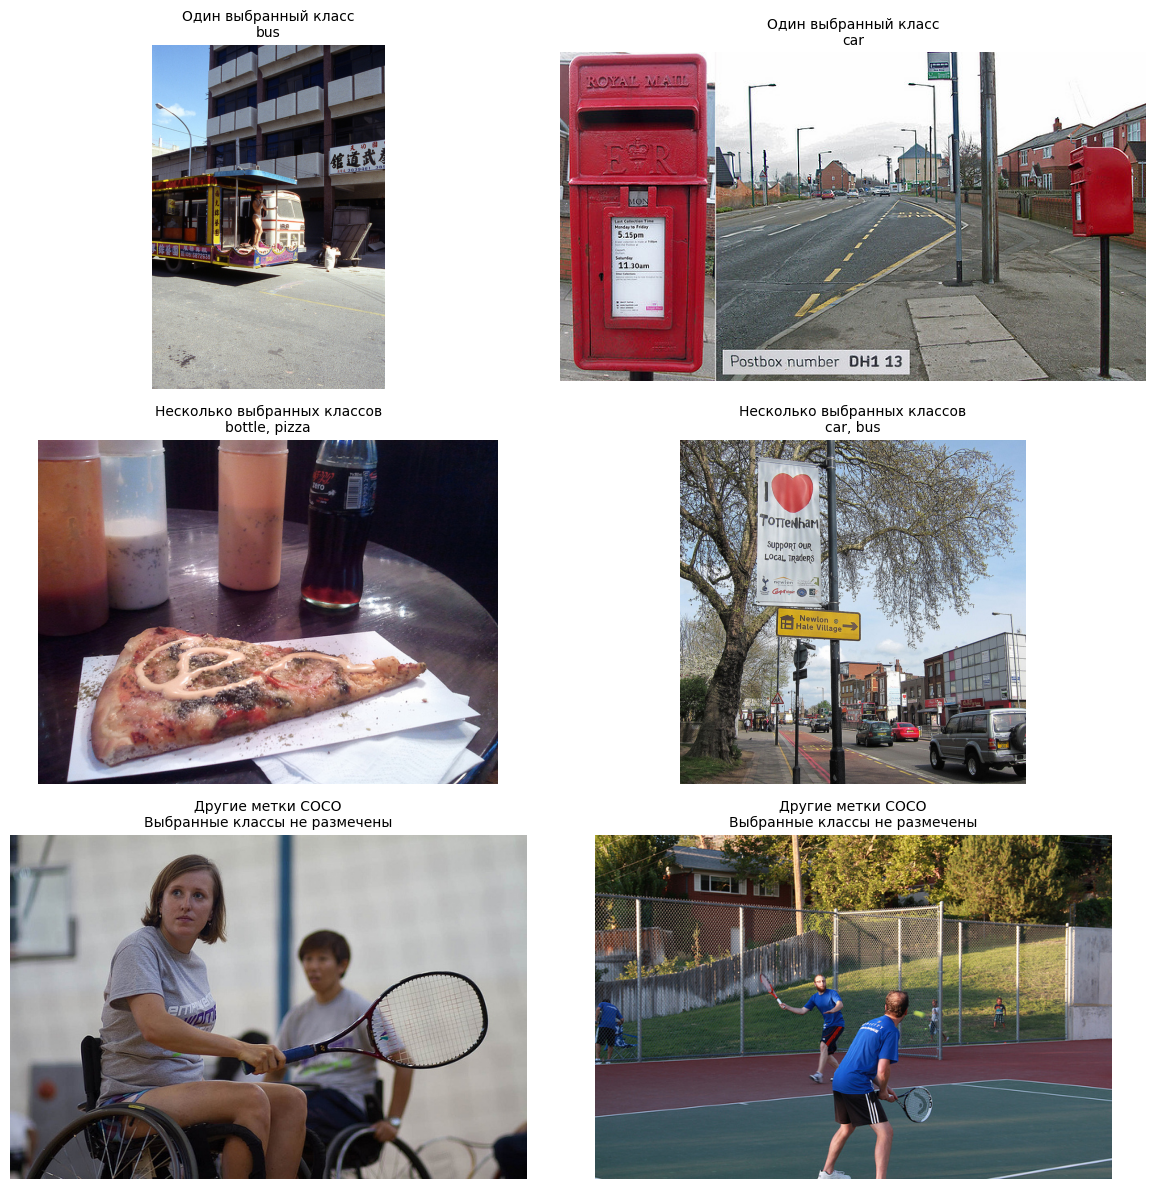

In [14]:
rng = np.random.default_rng(SEED)
example_groups = (
    ("Один выбранный класс", targets_per_image == 1),
    ("Несколько выбранных классов", targets_per_image > 1),
    ("Другие метки COCO", targets_per_image == 0),
)
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
for row, (group_name, mask) in enumerate(example_groups):
    chosen = rng.choice(np.flatnonzero(mask), size=2, replace=False)
    for axis, index in zip(axes[row], chosen, strict=False):
        item = images[index]
        with Image.open(IMAGE_DIR / item["file_name"]) as image:
            axis.imshow(image.convert("RGB"))
        names = [TARGETS[column] for column in np.flatnonzero(labels[index])]
        caption = ", ".join(names) if names else "Выбранные классы не размечены"
        axis.set_title(group_name + "\n" + textwrap.fill(caption, 45), fontsize=10)
        axis.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT / "image_examples.png", dpi=150)
plt.show()

### Как ошибки модели связаны с задачей игры

Ложное подтверждение возникает, когда игра засчитывает фото, хотя нужный предмет на нём отсутствует. В учебной игре это особенно нежелательно — ребёнок получает подтверждение неправильной находки. Поэтому измеряем **FAR (False Acceptance Rate)**, долю ошибочно принятых фото среди всех отрицательных примеров для задания. Формула имеет вид `FP / (FP + TN)`, где FP — ложные подтверждения, а TN — правильные отклонения. Если из 100 фотографий без банана модель приняла пять, FAR равен 5%.

Обратную ошибку тоже учитываем. Когда предмет есть, а игра отклоняет фото, ребёнок вынужден пробовать снова. **Recall**, или полнота, показывает долю принятых фото среди положительных примеров. Например, 80 принятых снимков из 100 фотографий с бананом дают recall 80%.

В этом сравнении положительный пример определяется наличием метки COCO. Такое правило позволяет воспроизвести эксперимент. Для следующего этапа нужны фотографии, снятые в условиях игры, и проверка разметки спорных случаев. Отдельно стоит изучить мелкие предметы и сцены с несколькими объектами, которые видны в EDA.

## 4. Модели и настройки

**YOLOv8n** берём как компактный baseline, а **YOLO11n** — как более новую модель того же семейства. Обе возвращают классы, уверенность и рамки объектов. Используем одинаковые настройки — размер входа 640, минимальный score `conf=0.001`, NMS IoU 0.7 и максимум 300 детекций. Низкий порог сохраняет слабые ответы, которые нужны для сравнения ранжирования и последующего выбора порога подтверждения. Оценкой присутствия класса на фото служит максимальная уверенность среди его детекций, а при отсутствии детекций score равен нулю.

**MobileCLIP-S0** проверяем как способ сопоставить фотографию с текстовым заданием. Для каждого класса используем один фиксированный шаблон `a photo of {object}.`. Модель обрабатывает весь кадр с предобработкой 256×256. Её score — косинусное сходство изображения и текста, поэтому порог для него подбираем отдельно от порогов YOLO.

Все веса предобучены и используются без дообучения. Детекторы знакомы с категориями COCO по обучению на COCO train2017. Текущий val2017 позволяет сравнить подходы на открытом наборе, а качество на снимках из игры предстоит измерить отдельно.

Batch 64 для MobileCLIP и 32 для YOLO позволяют выполнить прогон на GPU T4. Значение `num_workers=0` упрощает запуск в Kaggle. Версии весов и настройки сохраняются вместе с результатами.

In [15]:
CHECKPOINTS = {
    "mobileclip_s0.pt": (
        "https://docs-assets.developer.apple.com/ml-research/"
        "datasets/mobileclip/mobileclip_s0.pt"
    ),
    "yolov8n.pt": ("https://github.com/ultralytics/assets/releases/" "download/v8.3.0/yolov8n.pt"),
    "yolo11n.pt": ("https://github.com/ultralytics/assets/releases/" "download/v8.3.0/yolo11n.pt"),
}
EXPECTED_WEIGHTS = {
    "mobileclip_s0.pt": ("809b408eff74f8058843e86a1f92967097d42ba782450e85b8f4867b7f0ca0b7"),
    "yolov8n.pt": ("f59b3d833e2ff32e194b5bb8e08d211dc7c5bdf144b90d2c8412c47ccfc83b36"),
    "yolo11n.pt": ("0ebbc80d4a7680d14987a577cd21342b65ecfd94632bd9a8da63ae6417644ee1"),
}

In [16]:
def get_checkpoint(filename):
    path = OUTPUT / "models" / filename
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.is_file():
        print("Скачивание:", filename)
        temporary = path.with_suffix(".download")
        urllib.request.urlretrieve(CHECKPOINTS[filename], temporary)
        temporary.replace(path)
    digest = sha256(path)
    if digest != EXPECTED_WEIGHTS[filename]:
        raise ValueError(f"Не совпал SHA-256 checkpoint: {filename}")
    return path


weight_paths = {name: get_checkpoint(name) for name in CHECKPOINTS}
display(
    pd.DataFrame(
        [
            {"checkpoint": name, "PyTorch_MiB": path.stat().st_size / 2**20}
            for name, path in weight_paths.items()
        ]
    )
)

Скачивание: mobileclip_s0.pt
Скачивание: yolov8n.pt
Скачивание: yolo11n.pt


,checkpoint,PyTorch_MiB
0,mobileclip_s0.pt,205.931333
1,yolov8n.pt,6.246372
2,yolo11n.pt,5.353703


In [17]:
class COCODataset(Dataset):
    def __init__(self, images, image_dir, transform):
        self.images = images
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        item = self.images[index]
        with Image.open(self.image_dir / item["file_name"]) as image:
            tensor = self.transform(image.convert("RGB"))
        return tensor, item["id"]

In [18]:
def mobileclip_scores(images, image_dir, checkpoint, device, batch_size, workers):
    import mobileclip

    model, _, preprocess = mobileclip.create_model_and_transforms(
        "mobileclip_s0",
        pretrained=str(checkpoint),
        reparameterize=True,
        device=str(device),
    )
    model.eval()
    tokenizer = mobileclip.get_tokenizer("mobileclip_s0")
    tokens = tokenizer([f"a photo of {PROMPTS[target]}." for target in TARGETS]).to(device)
    with torch.inference_mode():
        text_features = F.normalize(model.encode_text(tokens).float(), dim=-1)
    loader = DataLoader(
        COCODataset(images, image_dir, preprocess),
        batch_size=batch_size,
        shuffle=False,
        num_workers=workers,
        pin_memory=True,
        persistent_workers=workers > 0,
    )
    scores = np.empty((len(images), len(TARGETS)), dtype=np.float32)
    row = 0
    for batch, _ in tqdm(loader, desc="MobileCLIP-S0", unit="batch"):
        batch = batch.to(device, non_blocking=True)
        with torch.inference_mode():
            features = model.encode_image(batch)
            features = F.normalize(features.float(), dim=-1)
            batch_scores = features @ text_features.T
        count = len(batch_scores)
        scores[row : row + count] = batch_scores.float().cpu().numpy()
        row += count
    if row != len(images):
        raise RuntimeError(f"MobileCLIP processed {row} of {len(images)} images")
    return scores

In [19]:
# Full fresh inference: do not reuse scores from an earlier code version.
model_scores = {}
model_scores["MobileCLIP-S0"] = mobileclip_scores(
    images,
    IMAGE_DIR,
    weight_paths["mobileclip_s0.pt"],
    DEVICE,
    batch_size=64,
    workers=0,
)
assert model_scores["MobileCLIP-S0"].shape == labels.shape
torch.cuda.empty_cache()

MobileCLIP-S0:   0%|          | 0/79 [00:00<?, ?batch/s]

In [20]:
def collect_yolo_batch(results, items, names, scores, detections, offset):
    target_columns = {name: i for i, name in enumerate(TARGETS)}
    for index, (item, result) in enumerate(zip(items, results, strict=False)):
        if result.boxes is None:
            continue
        class_ids = result.boxes.cls.cpu().numpy().astype(int)
        confidences = result.boxes.conf.cpu().numpy()
        boxes = result.boxes.xyxy.cpu().numpy()
        for class_id, confidence, box in zip(class_ids, confidences, boxes, strict=False):
            target = names[int(class_id)]
            column = target_columns.get(target)
            if column is None:
                continue
            row = offset + index
            scores[row, column] = max(scores[row, column], confidence)
            detections[target].append((float(confidence), item["id"], box.tolist()))

In [21]:
def yolo_scores_and_boxes(name, checkpoint, batch_size=32):
    model = YOLO(str(checkpoint))
    scores = np.zeros(labels.shape, dtype=np.float32)
    detections = defaultdict(list)
    processed = 0
    for offset in tqdm(range(0, len(images), batch_size), desc=name):
        items = images[offset : offset + batch_size]
        paths = [str(IMAGE_DIR / item["file_name"]) for item in items]
        results = model.predict(
            source=paths,
            stream=False,
            imgsz=640,
            conf=0.001,
            iou=0.7,
            device=0,
            batch=len(paths),
            max_det=300,
            verbose=False,
        )
        assert len(results) == len(items)
        collect_yolo_batch(results, items, model.names, scores, detections, offset)
        processed += len(items)
    assert processed == len(images)
    return scores, detections

In [22]:
model_detections = {}
for name in ("yolov8n", "yolo11n"):
    scores, detections = yolo_scores_and_boxes(name, weight_paths[f"{name}.pt"])
    model_scores[name] = scores
    model_detections[name] = detections
    torch.cuda.empty_cache()

for name, scores in model_scores.items():
    assert scores.shape == (len(images), len(TARGETS)), name
    assert np.isfinite(scores).all(), name
np.savez_compressed(
    OUTPUT / "full_coco_scores.npz",
    image_ids=image_ids,
    targets=np.asarray(TARGETS),
    labels=labels,
    **model_scores,
)

yolov8n:   0%|          | 0/157 [00:00<?, ?it/s]

yolo11n:   0%|          | 0/157 [00:00<?, ?it/s]

## 5. Почему выбраны эти метрики и как подбираются пороги

Основная метрика сравнения — **macro AP**. Для каждого класса Average Precision показывает, насколько хорошо модель ставит фотографии с нужным предметом выше отрицательных примеров с учётом precision и recall. Это позволяет сравнить ранжирование до выбора рабочего порога. Затем усредняем AP по классам с одинаковым весом, чтобы многочисленные фотографии машин не определяли результат за остальные игровые задания.

AP подходит для наших данных, поскольку положительные примеры составляют небольшую часть фотографий для каждого задания. Для ориентира AP случайного ранжирования примерно равен доле положительных примеров, которую мы посчитали в EDA. Чем больше ложных подтверждений оказывается среди высоких оценок модели, тем сильнее это отражается на precision и AP.

**ROC AUC** оставляем дополнительной метрикой. Она показывает, насколько часто случайное положительное фото получает score выше случайного отрицательного. При большом числе отрицательных примеров ROC AUC может выглядеть высоким даже при неудобном для игры количестве ложных подтверждений, поэтому модель выбираем прежде всего по AP и проверяем её recall и FAR при рабочем пороге.

В сводной таблице ROC AUC, recall и FAR тоже усредняем по классам с одинаковым весом. Результаты отдельных заданий показываем на графиках, поскольку среднее может скрыть сложный класс.

Для порогового сравнения задаём ориентир **FAR не выше 5%**. Это выбранное условие учебного эксперимента. Допустимую частоту ошибок для продукта предстоит согласовать и проверить на целевых данных. В рамках этого условия стремимся сохранить как можно больше правильных находок, то есть получить высокий recall.

Порог калибруем отдельно для каждого класса и каждой модели. Делим данные на пять стратифицированных фолдов с одинаковым seed. На четырёх частях подбираем порог по отрицательным примерам, на пятой измеряем ответы. Повторяем процедуру для всех фолдов и объединяем отложенные ответы. Полученные recall и FAR обозначаем `oof` (out-of-fold). AP и ROC AUC считаем по исходным score всех фото, поскольку эти метрики обходятся без порога, а веса моделей зафиксированы.

Сравним два варианта калибровки. **Эмпирический порог** допускает до 5% ложных подтверждений среди калибровочных отрицательных примеров. **Консервативный порог** (`confidence_95pct`) добавляет запас по односторонней биномиальной границе с уровнем доверия 95%. Такой запас учитывает конечный объём калибровки при предположении независимых примеров из одного распределения. Фактический FAR на отложенных фото измеряем в обоих случаях и отдельно отмечаем классы, где он превысил 5%.

Фото засчитывается при строгом условии `score > cutoff`. Благодаря этому нулевые оценки YOLO при отсутствии детекции остаются отклонёнными и при пороге, равном нулю.

In [23]:
def threshold_for_far(negative_scores, protocol="empirical_5pct"):
    """Return cutoff for STRICT score > cutoff, including tied scores."""
    negatives = np.asarray(negative_scores, dtype=np.float64)
    assert negatives.size and np.isfinite(negatives).all()
    count = len(negatives)
    allowed_fp = int(math.floor(FAR_TARGET * count))
    if protocol == "confidence_95pct":
        candidates = np.arange(allowed_fp + 1)
        valid = candidates[binom.cdf(candidates, count, FAR_TARGET) <= 1 - CONFIDENCE]
        if not len(valid):
            return np.inf
        allowed_fp = int(valid[-1])
    elif protocol != "empirical_5pct":
        raise ValueError(protocol)
    cutoff = float(np.sort(negatives)[::-1][allowed_fp])
    # No nextafter: a float64 epsilon may disappear in float32 comparisons.
    assert np.mean(negatives > cutoff) <= FAR_TARGET
    return cutoff

In [24]:
# Regression checks: zero scores must never become positive at cutoff zero.
for negative_scores in (
    np.zeros(100, dtype=np.float32),
    np.array([0] * 94 + [0.1] * 6, dtype=np.float32),
    np.linspace(-1, 1, 100, dtype=np.float32),
):
    for protocol in ("empirical_5pct", "confidence_95pct"):
        cutoff = threshold_for_far(negative_scores, protocol)
        assert np.mean(negative_scores > cutoff) <= FAR_TARGET
assert not np.any(np.zeros(100, dtype=np.float32) > 0.0)

In [25]:
def evaluate_class_oof(y, scores, model, target, protocol):
    cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=SEED)
    predicted = np.zeros(len(y), dtype=bool)
    folds = np.full(len(y), -1, dtype=int)
    calibration = []
    for fold, (calibration_idx, test_idx) in enumerate(cv.split(scores, y)):
        negatives = scores[calibration_idx][y[calibration_idx] == 0]
        cutoff = threshold_for_far(negatives, protocol)
        calibration_far = float(np.mean(negatives > cutoff))
        assert calibration_far <= FAR_TARGET
        predicted[test_idx] = scores[test_idx] > cutoff
        folds[test_idx] = fold
        calibration.append(
            {
                "model": model,
                "target": target,
                "protocol": protocol,
                "fold": fold,
                "cutoff": cutoff,
                "calibration_far": calibration_far,
                "calibration_negatives": len(negatives),
                "test_positives": int(y[test_idx].sum()),
            }
        )
    assert (folds >= 0).all()
    tp = int(np.sum(predicted & (y == 1)))
    fp = int(np.sum(predicted & (y == 0)))
    return tp, fp, predicted, folds, calibration

In [26]:
def evaluate_presence(name, scores):
    rows, calibration_rows, predictions = [], [], {}
    for column, target in enumerate(TARGETS):
        y = labels[:, column]
        values = scores[:, column]
        positives = int(y.sum())
        negatives = len(y) - positives
        assert positives >= MIN_POSITIVE_IMAGES and negatives >= CV_SPLITS
        for protocol in ("empirical_5pct", "confidence_95pct"):
            tp, fp, pred, folds, calibration = evaluate_class_oof(y, values, name, target, protocol)
            rows.append(
                {
                    "model": name,
                    "target": target,
                    "protocol": protocol,
                    "positive_images": positives,
                    "negative_images": negatives,
                    "average_precision": average_precision_score(y, values),
                    "roc_auc": roc_auc_score(y, values),
                    "recall_oof": tp / positives,
                    "far_oof": fp / negatives,
                    "oof_true_positives": tp,
                    "oof_false_positives": fp,
                    "far_exceeds_target": fp / negatives > FAR_TARGET,
                }
            )
            calibration_rows.extend(calibration)
            predictions[f"{target}__{protocol}"] = pred
            predictions[f"{target}__fold"] = folds
    np.savez_compressed(OUTPUT / f"{name}_oof.npz", **predictions)
    return rows, calibration_rows

In [27]:
per_class_rows, calibration_rows = [], []
for name, scores in model_scores.items():
    rows, fold_rows = evaluate_presence(name, scores)
    per_class_rows.extend(rows)
    calibration_rows.extend(fold_rows)
per_class = pd.DataFrame(per_class_rows)
calibration = pd.DataFrame(calibration_rows)
per_class.to_csv(OUTPUT / "per_class_metrics.csv", index=False)
calibration.to_csv(OUTPUT / "calibration_folds.csv", index=False)
assert calibration["calibration_far"].le(FAR_TARGET).all()

model_metrics = (
    per_class.groupby(["model", "protocol"], sort=False)
    .agg(
        macro_ap=("average_precision", "mean"),
        macro_auc=("roc_auc", "mean"),
        macro_recall_oof=("recall_oof", "mean"),
        macro_far_oof=("far_oof", "mean"),
        classes_far_above_5pct=("far_exceeds_target", "sum"),
        max_class_far=("far_oof", "max"),
    )
    .reset_index()
)
model_metrics.to_csv(OUTPUT / "model_metrics.csv", index=False)
summary = model_metrics.replace(
    {
        "protocol": {
            "empirical_5pct": "Эмпирический",
            "confidence_95pct": "Консервативный",
        }
    }
).rename(
    columns={
        "model": "Модель",
        "protocol": "Порог",
        "macro_ap": "Macro AP",
        "macro_auc": "ROC AUC",
        "macro_recall_oof": "Recall",
        "macro_far_oof": "FAR",
        "classes_far_above_5pct": "Классов с FAR > 5%",
        "max_class_far": "Максимальный FAR",
    }
)
display(summary.round(4))

,Модель,Порог,Macro AP,ROC AUC,Recall,FAR,Классов с FAR > 5%,Максимальный FAR
0,MobileCLIP-S0,Эмпирический,0.5971,0.8919,0.6808,0.0500,13,0.0511
1,MobileCLIP-S0,Консервативный,0.5971,0.8919,0.6715,0.0441,0,0.0456
2,yolov8n,Эмпирический,0.8061,0.9592,0.8841,0.0499,17,0.0511
3,yolov8n,Консервативный,0.8061,0.9592,0.8759,0.0442,0,0.0464
4,yolo11n,Эмпирический,0.8213,0.9561,0.8911,0.0473,12,0.0512
5,yolo11n,Консервативный,0.8213,0.9561,0.8843,0.0426,0,0.0449


In [28]:
# Подробные значения обоих протоколов сохранены в per_class_metrics.csv.
part = per_class.loc[per_class["protocol"].eq("confidence_95pct")]
failures = part.loc[
    part["far_exceeds_target"],
    ["model", "target", "far_oof", "recall_oof", "positive_images"],
]
display(
    Markdown(
        f"При консервативном пороге превышение FAR 5% встретилось в "
        f"**{len(failures)} из {len(part)} сочетаний модели и класса**. "
        "Ниже сравним recall и FAR по каждому классу, чтобы увидеть, "
        "какие задания скрываются за средними значениями."
    )
)
if not failures.empty:
    display(failures.round(4))

При консервативном пороге превышение FAR 5% встретилось в **0 из 78 сочетаний модели и класса**. Ниже сравним recall и FAR по каждому классу, чтобы увидеть, какие задания скрываются за средними значениями.

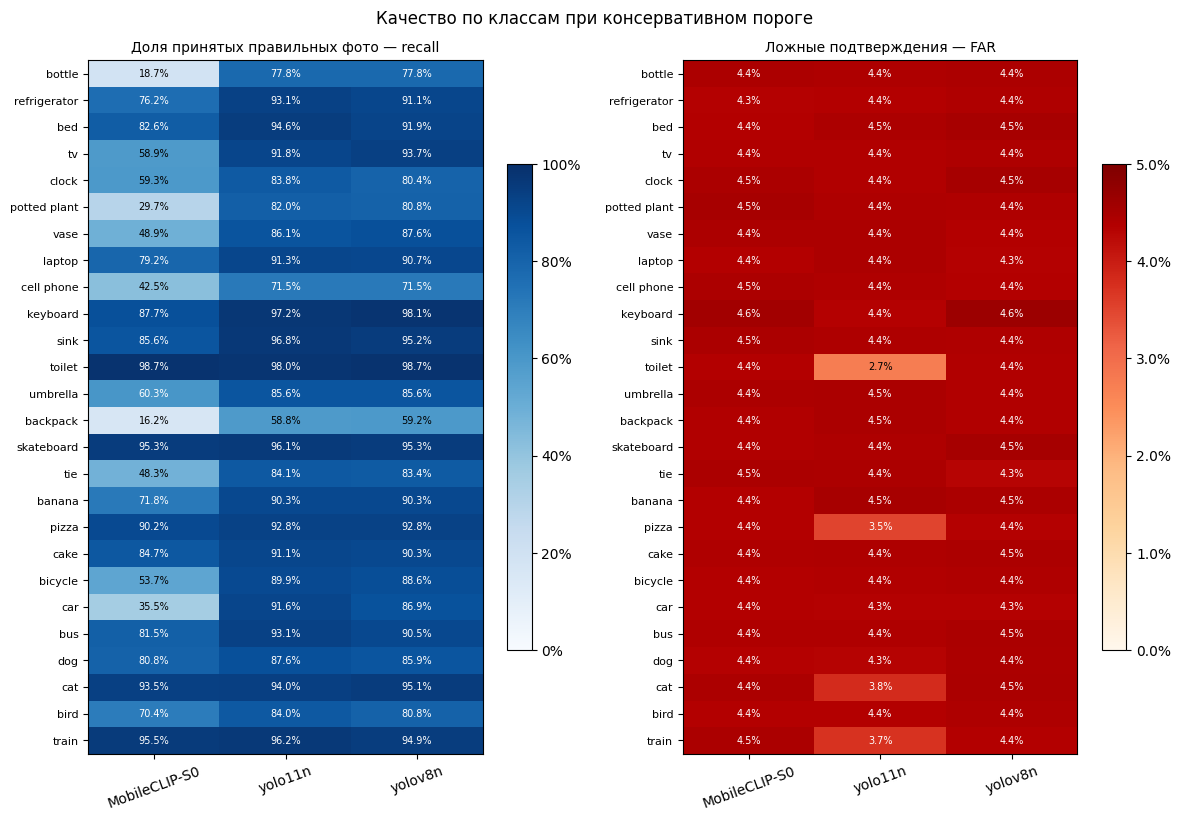

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, max(7, len(TARGETS) * 0.32)))
for axis, metric, title, upper, cmap in zip(
    axes,
    ("recall_oof", "far_oof"),
    ("Доля принятых правильных фото — recall", "Ложные подтверждения — FAR"),
    (1.0, FAR_TARGET),
    ("Blues", "OrRd"),
    strict=False,
):
    table = part.pivot(index="target", columns="model", values=metric)
    table = table.reindex(TARGETS)
    plot = axis.imshow(table, vmin=0, vmax=upper, aspect="auto", cmap=cmap)
    axis.set_xticks(range(len(table.columns)), table.columns, rotation=20)
    axis.set_yticks(range(len(TARGETS)), table.index, fontsize=8)
    axis.set_title(title, fontsize=10)
    for row in range(len(TARGETS)):
        for column in range(len(table.columns)):
            value = table.iloc[row, column]
            axis.text(
                column,
                row,
                f"{value:.1%}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if value > upper * 0.6 else "black",
            )
    fig.colorbar(plot, ax=axis, shrink=0.7, format=PercentFormatter(1))
fig.suptitle("Качество по классам при консервативном пороге")
fig.tight_layout()
fig.savefig(OUTPUT / "recall_far_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

Средние метрики дают общий ориентир, а графики по классам помогают определить состав игровых заданий. При одинаковом ограничении на FAR низкий recall означает, что правильную находку часто придётся фотографировать заново. Если FAR класса превышает 5%, его порог требует дополнительной проверки. Численные результаты обоих вариантов калибровки сохраняются в `per_class_metrics.csv`.

### Разбор ошибок по сохранённым ответам

У YOLO11n самые сложные из рассмотренных домашних предметов — рюкзак, телефон и бутылка. Для них посмотрим количество пропусков и ложных подтверждений при консервативном пороге. Для каждого класса выберем ложное подтверждение с наибольшим score и пропуск с наименьшим score. При равных оценках используем порядок COCO ID.

Этот раздел добавлен на CPU по сохранённым score и out-of-fold ответам после прогона Kaggle. Основной прогон и его метрики сохранены. Код ниже также выполняется при обычном запуске ноутбука сверху вниз.

In [35]:
ERROR_MODEL = "yolo11n"
ERROR_PROTOCOL = "confidence_95pct"
ERROR_TARGETS = ["backpack", "cell phone", "bottle"]
error_records = []
error_summary_rows = []
calibration_table = pd.read_csv(OUTPUT / "calibration_folds.csv")

with (
    np.load(OUTPUT / "full_coco_scores.npz", allow_pickle=False) as saved_scores,
    np.load(OUTPUT / f"{ERROR_MODEL}_oof.npz", allow_pickle=False) as saved_oof,
):
    saved_targets = saved_scores["targets"].tolist()
    for target in ERROR_TARGETS:
        column = saved_targets.index(target)
        truth = saved_scores["labels"][:, column].astype(bool)
        values = saved_scores[ERROR_MODEL][:, column]
        predicted = saved_oof[f"{target}__{ERROR_PROTOCOL}"]
        folds = saved_oof[f"{target}__fold"]
        false_positive = predicted & ~truth
        false_negative = ~predicted & truth
        positives = int(truth.sum())
        negatives = len(truth) - positives
        error_summary_rows.append(
            {
                "target": target,
                "positive_images": positives,
                "true_positives": int((predicted & truth).sum()),
                "false_negatives": int(false_negative.sum()),
                "false_positives": int(false_positive.sum()),
                "recall": float((predicted & truth).sum() / positives),
                "far": float(false_positive.sum() / negatives),
            }
        )
        cutoffs = (
            calibration_table.loc[
                calibration_table["model"].eq(ERROR_MODEL)
                & calibration_table["target"].eq(target)
                & calibration_table["protocol"].eq(ERROR_PROTOCOL)
            ]
            .set_index("fold")["cutoff"]
            .to_dict()
        )
        for kind, mask in (
            ("false_positive", false_positive),
            ("false_negative", false_negative),
        ):
            indices = np.flatnonzero(mask)
            # Максимальный score для FP, минимальный для FN.
            ordering_scores = -values[indices] if kind == "false_positive" else values[indices]
            order = np.argsort(ordering_scores, kind="stable")
            for rank, index in enumerate(indices[order]):
                image_id = int(saved_scores["image_ids"][index])
                fold = int(folds[index])
                error_records.append(
                    {
                        "model": ERROR_MODEL,
                        "protocol": ERROR_PROTOCOL,
                        "target": target,
                        "error_type": kind,
                        "image_id": image_id,
                        "file_name": f"{image_id:012d}.jpg",
                        "score": float(values[index]),
                        "cutoff": cutoffs[fold],
                        "fold": fold,
                        "selected_example": rank == 0,
                    }
                )

error_cases = pd.DataFrame(error_records)
error_cases.to_csv(OUTPUT / "error_cases.csv", index=False)
error_summary = pd.DataFrame(error_summary_rows)
error_table = error_summary.rename(
    columns={
        "target": "Класс",
        "positive_images": "Положительных фото",
        "true_positives": "Подтверждено",
        "false_negatives": "Пропуски",
        "false_positives": "Ложные подтверждения",
        "recall": "Recall",
        "far": "FAR",
    }
)
error_table["Recall"] = error_table["Recall"].map("{:.1%}".format)
error_table["FAR"] = error_table["FAR"].map("{:.2%}".format)
display(error_table)

,Класс,Положительных фото,Подтверждено,Пропуски,Ложные подтверждения,Recall,FAR
0,backpack,228,134,94,213,58.8%,4.46%
1,cell phone,214,153,61,211,71.5%,4.41%
2,bottle,379,295,84,204,77.8%,4.41%


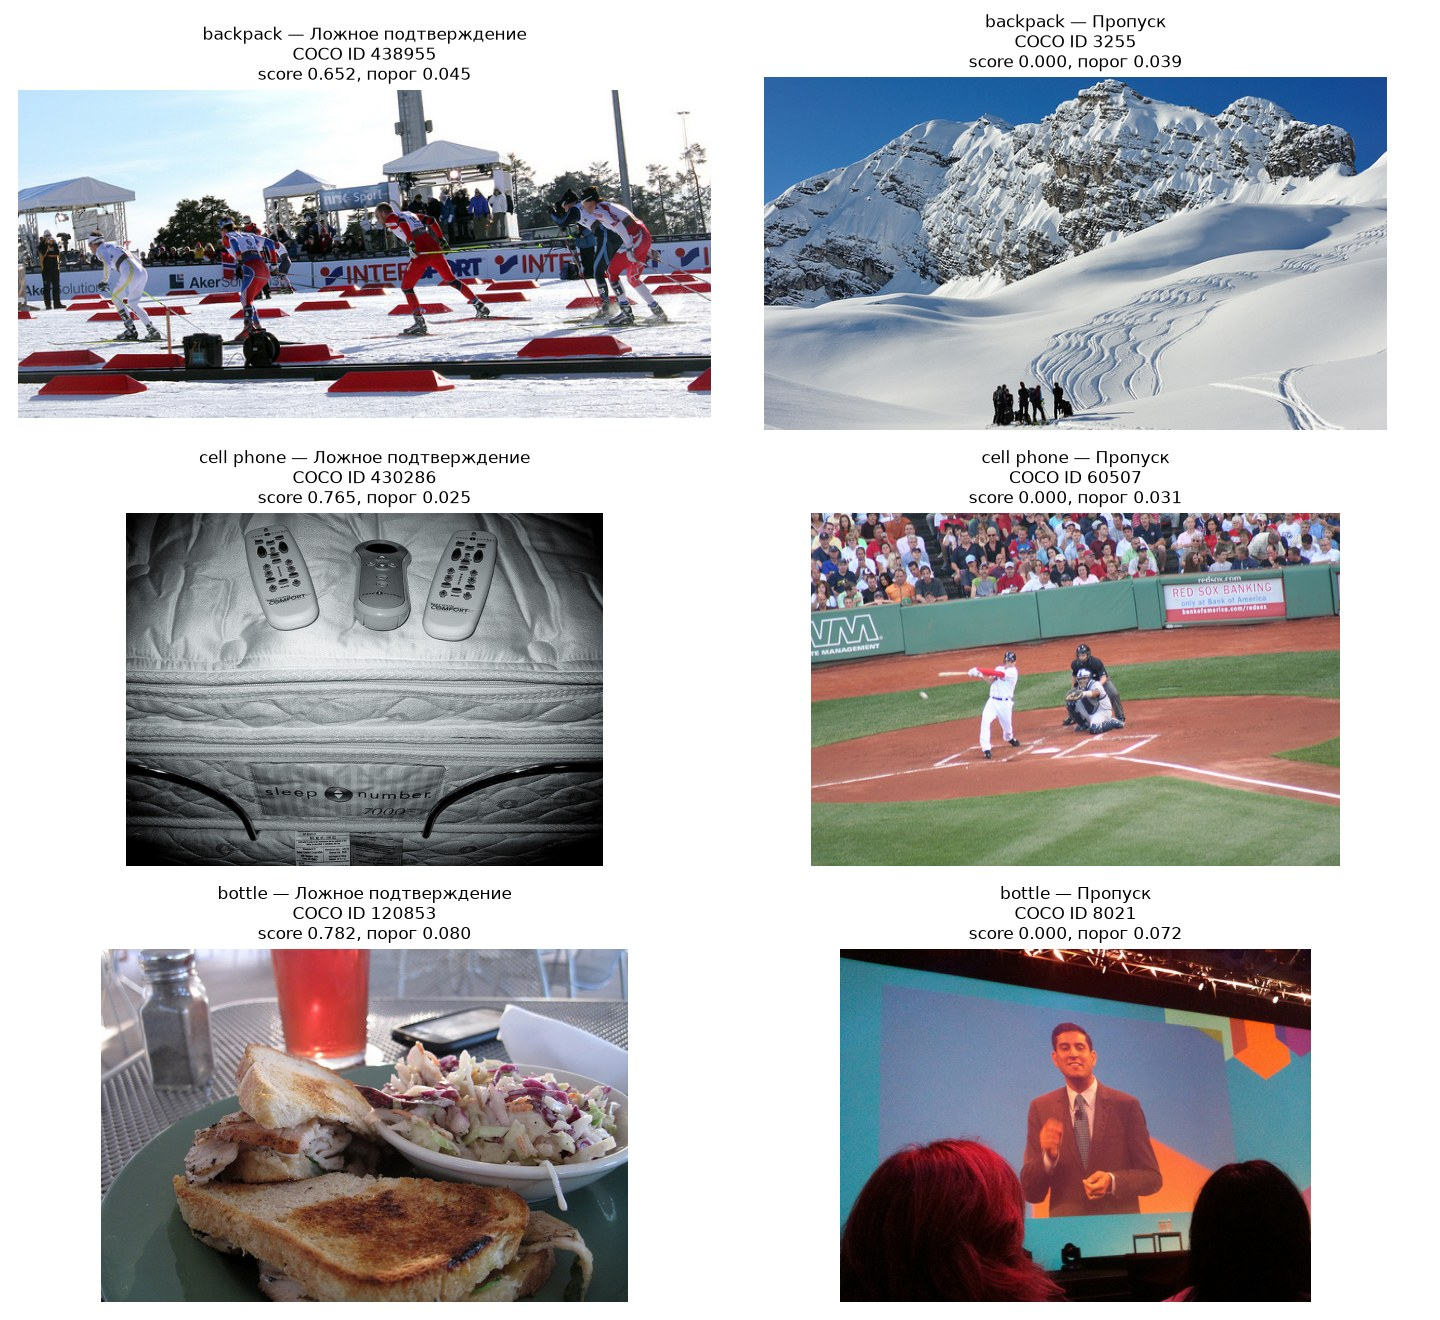

In [36]:
from IPython.display import Image as NotebookImage

examples = error_cases.loc[error_cases["selected_example"]]
fig, axes = plt.subplots(len(ERROR_TARGETS), 2, figsize=(12, 11))
for axis, row in zip(axes.flat, examples.itertuples(), strict=True):
    with Image.open(IMAGE_DIR / row.file_name) as image:
        axis.imshow(image.convert("RGB"))
    kind = "Ложное подтверждение" if row.error_type == "false_positive" else "Пропуск"
    axis.set_title(
        f"{row.target} — {kind}\nCOCO ID {row.image_id}\n"
        f"score {row.score:.3f}, порог {row.cutoff:.3f}",
        fontsize=10,
    )
    axis.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT / "error_examples.jpg", dpi=120, pil_kwargs={"quality": 88})
plt.close(fig)
display(NotebookImage(filename=str(OUTPUT / "error_examples.jpg")))

На фото COCO ID 430286 модель подтверждает телефон с оценкой 0,765, хотя на снимке видны пульты управления. Это показательный пример похожих по форме предметов. Пропущенный телефон на фото 60507 размечен в кадре с бейсбольным матчем и зрителями. У пропущенного рюкзака 3255 нужный предмет находится в далёкой группе людей на фоне гор.

В ложном подтверждении рюкзака 438955 видны сумки у спортивной трассы. На фото 120853 с ложным подтверждением бутылки есть еда, посуда и небольшие ёмкости. Такие случаи стоит проверять на границы категорий и возможные пропуски разметки. Пропуск бутылки 8021 приходится на сцену с большим экраном. У всех трёх выбранных пропусков score равен нулю.

Архив сохраняет score присутствия и итоговую метрику рамок. Для установления конкретного объекта, вызвавшего ложное подтверждение, понадобятся его детекции. Поэтому наблюдения по шести примерам считаем гипотезами о причинах ошибок, а частоту оцениваем по всем ответам. Исходные метки сохранены. Таблица `error_cases.csv` содержит все ошибки этих трёх классов, их COCO ID, оценки, пороги и фолды.

## 6. Насколько точны рамки YOLO

Дополнительно проверим локализацию объектов у двух детекторов. Используем COCOeval AP при IoU 0.50 по тому же выбранному набору классов. IoU измеряет долю пересечения предсказанной и истинной рамок относительно их объединения. При пороге 0.50 совпадение засчитывается, если эта доля составляет хотя бы половину.

Эта метрика помогает понять, насколько пригодны рамки для следующего этапа, например для проверки цвета внутри предмета. Основной macro AP выше оценивает присутствие предмета на целом фото. MobileCLIP возвращает сходство с текстом, поэтому участвует в сравнении присутствия.

In [30]:
def official_detection_ap50(detections):
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    category_ids = {name: cid for cid, name in categories.items()}
    results = []
    for target, items in detections.items():
        for confidence, image_id, (x1, y1, x2, y2) in items:
            results.append(
                {
                    "image_id": int(image_id),
                    "category_id": category_ids[target],
                    "bbox": [x1, y1, x2 - x1, y2 - y1],
                    "score": confidence,
                }
            )
    with redirect_stdout(io.StringIO()):
        truth = COCO(str(ANNOTATION_PATH))
        predicted = truth.loadRes(results)
        evaluator = COCOeval(truth, predicted, "bbox")
        evaluator.params.catIds = sorted(category_ids[t] for t in TARGETS)
        evaluator.params.imgIds = image_ids.tolist()
        evaluator.params.iouThrs = np.array([0.5])
        evaluator.evaluate()
        evaluator.accumulate()
    precision = evaluator.eval["precision"][0, :, :, 0, -1]
    ap_by_id = {}
    for column, category_id in enumerate(evaluator.params.catIds):
        valid = precision[:, column]
        ap_by_id[category_id] = float(valid[valid >= 0].mean())
    return [{"target": t, "ap50": ap_by_id[category_ids[t]]} for t in TARGETS]

In [31]:
detection_rows = []
for name, detections in model_detections.items():
    for row in official_detection_ap50(detections):
        detection_rows.append({"model": name, **row})
detection_metrics = pd.DataFrame(detection_rows)
detection_metrics.to_csv(OUTPUT / "detection_ap50.csv", index=False)
display(detection_metrics.groupby("model")["ap50"].mean().to_frame())

,ap50
model,
yolo11n,0.591065
yolov8n,0.568255


In [32]:
conservative = model_metrics.loc[model_metrics["protocol"].eq("confidence_95pct")].sort_values(
    "macro_ap", ascending=False
)
leader = conservative.iloc[0]
failed = int(leader["classes_far_above_5pct"])
leader_classes = part.loc[part["model"].eq(leader["model"])]
weakest = leader_classes.sort_values("recall_oof").iloc[0]
conclusions = (
    "## 7. Что получилось\n\n"
    f"После фильтра по объёму данных сравнили модели на **{len(TARGETS)} "
    f"классах** и всех **{len(images):,} фото**. Из {PROJECT_TASK_COUNT} "
    f"исходных заданий {len(COCO_TASK_CLASSES)} имеют подходящую категорию "
    f"COCO, а {len(excluded_stats)} из них отложены из-за нехватки примеров.\n\n"
    f"Лучший macro AP получил **{leader['model']} — {leader['macro_ap']:.3f}**. "
    f"При консервативном пороге средний recall по классам составил "
    f"**{leader['macro_recall_oof']:.1%}**, средний FAR — "
    f"**{leader['macro_far_oof']:.2%}**. Превышение FAR 5% встретилось у "
    f"{failed} из {len(TARGETS)} классов.\n\n"
    f"Самый низкий recall у этой модели получил класс `{weakest['target']}` "
    f"— **{weakest['recall_oof']:.1%}** на {int(weakest['positive_images'])} "
    "положительных фото. Перед включением такого задания в игру стоит "
    "разобрать ошибки и проверить его на целевых снимках.\n\n"
    "Следующий шаг — собрать отдельные dev и test из фотографий, снятых "
    "в условиях игры. На dev можно выбрать пороги с учётом допустимой "
    "частоты ложных подтверждений, затем проверить их на test. "
    "Мелкие предметы и сцены с несколькими объектами стоит выделить "
    "в отдельные срезы."
)
display(Markdown(conclusions))
_ = (OUTPUT / "conclusions.md").write_text(conclusions, encoding="utf-8")

## 7. Что получилось

После фильтра по объёму данных сравнили модели на **26 классах** и всех **5,000 фото**. Из 58 исходных заданий 38 имеют подходящую категорию COCO, а 12 из них отложены из-за нехватки примеров.

Лучший macro AP получил **yolo11n — 0.821**. При консервативном пороге средний recall по классам составил **88.4%**, средний FAR — **4.26%**. Превышение FAR 5% встретилось у 0 из 26 классов.

Самый низкий recall у этой модели получил класс `backpack` — **58.8%** на 228 положительных фото. Перед включением такого задания в игру стоит разобрать ошибки и проверить его на целевых снимках.

Следующий шаг — собрать отдельные dev и test из фотографий, снятых в условиях игры. На dev можно выбрать пороги с учётом допустимой частоты ложных подтверждений, затем проверить их на test. Мелкие предметы и сцены с несколькими объектами стоит выделить в отдельные срезы.

## 8. Сохранение результатов

Таблицы, графики, score моделей и настройки эксперимента сохраняются в папку `photoquest-coco-min100` внутри `/kaggle/working/`. В `class_stats.csv` остаются все 38 сопоставленных классов и признак включения в сравнение. Итоговые метрики относятся только к классам, прошедшим фильтр. Для скачивания результатов также создаётся `hw2_results.zip`.

In [33]:
metadata = {
    "dataset": "COCO 2017 val",
    "kaggle_dataset": ("nikitamanaenkov/microsoft-coco-2017"),
    "images": len(images),
    "classes": TARGETS,
    "tasks": PROJECT_TASK_COUNT,
    "mapped_classes": COCO_TASK_CLASSES,
    "min_positive_images": MIN_POSITIVE_IMAGES,
    "excluded_classes": excluded_stats["target"].tolist(),
    "selection_rule": "positive_images >= min_positive_images",
    "small_object_rule": "noncrowd bbox area < 1% of image area",
    "yolo_settings": {"imgsz": 640, "conf": 0.001, "iou": 0.7, "max_det": 300, "batch_size": 32},
    "mobileclip_settings": {"batch_size": 64, "prompt": "a photo of {object}."},
    "annotation_sha256": annotation_hash,
    "seed": SEED,
    "cv_splits": CV_SPLITS,
    "far_target": FAR_TARGET,
    "confidence": CONFIDENCE,
    "comparison": "score > cutoff",
    "presence_crowd_policy": "crowd annotations count as presence",
    "torch": torch.__version__,
    "python": platform.python_version(),
    "gpu": torch.cuda.get_device_name(0),
    "mobileclip_commit": MOBILECLIP_COMMIT,
    "packages": {
        name: importlib.metadata.version(name)
        for name in (
            "numpy",
            "pandas",
            "scipy",
            "scikit-learn",
            "ultralytics",
            "matplotlib",
            "pycocotools",
            "open_clip_torch",
            "timm",
        )
    },
    "checkpoints": {name: sha256(path) for name, path in weight_paths.items()},
    "started_utc": STARTED_UTC,
    "elapsed_seconds": round(time.perf_counter() - STARTED, 1),
}
_ = (OUTPUT / "metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
)
freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
_ = (OUTPUT / "requirements-freeze.txt").write_text(freeze, encoding="utf-8")

In [34]:
assert len(per_class) == len(model_scores) * len(TARGETS) * 2
assert len(calibration) == len(per_class) * CV_SPLITS
assert len(image_audit) == len(images)
assert len(model_scores) == 3
archive = OUTPUT.parent / "hw2_results.zip"
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(OUTPUT.rglob("*")):
        if path.is_file() and "models" not in path.relative_to(OUTPUT).parts:
            bundle.write(path, path.relative_to(OUTPUT))